# Stats for Data Analytics – CA1
## Mongolia inbound foreign passengers by country (Jan 2023–Sep 2026)
**Dataset:** `DT_NSO_1800_004V2_20261028-055147(2).xlsx` (National Statistics Office of Mongolia).

This notebook uses only the latest Excel file. The worksheet stores months in reverse chronological order; the import code below converts them to dates and sorts observations chronologically. The unit of analysis is one country in one month (45 months × 4 countries = 180 observations).

**GitHub Repository:**

https://github.com/2026465-png/Stats-for-Data-Analytics-CA1

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom, poisson, norm, shapiro

FILE_PATH = "DT_NSO_1800_004V2_20261028-055147.xlsx"
raw = pd.read_excel(FILE_PATH, header=None)

# Verified layout in the supplied workbook: dates at row index 2, columns 2–46;
# country labels at rows 3–6, column 1; passenger counts in columns 2–46.
months = pd.to_datetime(raw.iloc[2, 2:47], format="%Y-%m")
records = []
for row in range(3, 7):
    country = str(raw.iloc[row, 1]).strip()
    if "Democratic" in country:
        country = "North Korea"
    for col, month in enumerate(months, start=2):
        records.append({"Month": month, "Country": country,
                        "Passengers": pd.to_numeric(raw.iloc[row, col])})

df = pd.DataFrame(records).sort_values(["Month", "Country"]).reset_index(drop=True)
df["Year"] = df["Month"].dt.year
df["Month_Number"] = df["Month"].dt.month
df["Quarter"] = "Q" + df["Month"].dt.quarter.astype(str)
df["Passengers_Thousands"] = df["Passengers"] / 1000

print("Shape:", df.shape)
print("Date range:", df["Month"].min().date(), "to", df["Month"].max().date())
print("Missing values:\n", df.isna().sum())
print("Duplicate country-month rows:", df.duplicated(["Month", "Country"]).sum())
df.head()

Shape: (180, 7)
Date range: 2023-01-01 to 2026-09-01
Missing values:
 Month                   0
Country                 0
Passengers              0
Year                    0
Month_Number            0
Quarter                 0
Passengers_Thousands    0
dtype: int64
Duplicate country-month rows: 0


,Month,Country,Passengers,Year,Month_Number,Quarter,Passengers_Thousands
0,2023-01-01,China,1935,2023,1,Q1,1.935
1,2023-01-01,Korea,2343,2023,1,Q1,2.343
2,2023-01-01,North Korea,2,2023,1,Q1,0.002
3,2023-01-01,Russia,13404,2023,1,Q1,13.404
4,2023-02-01,China,4301,2023,2,Q1,4.301


## 1. Descriptive statistics
`Country` is categorical. `Passengers` is a quantitative count. `Year`, `Month_Number` and `Quarter` are derived time descriptors; they do not represent independent measured outcomes. Country-level summaries are more meaningful than pooling the four countries because their passenger volumes differ greatly.

In [ ]:
# Overall and country-level descriptive statistics
print(df["Passengers"].describe())
summary = df.groupby("Country")["Passengers"].agg(
    ["count", "mean", "median", "std", "var", "min", "max", "sum"]
).round(2)
display(summary)

# Monthly total across the four countries
monthly_total = df.groupby("Month", as_index=False)["Passengers"].sum()
print(monthly_total["Passengers"].describe().round(2))

## 2. Visual exploration
The figures compare the time trend, distribution by country and month-of-year pattern. Because country counts have very different scales, interpret the North Korea series separately or use a logarithmic scale when comparing all countries.

In [ ]:
# Graph 1: monthly trend, one line per country
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x="Month", y="Passengers", hue="Country", marker="o")
plt.title("Monthly inbound passengers to Mongolia by country")
plt.xlabel("Month"); plt.ylabel("Passengers"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Graph 2: distribution by country (log scale makes low-volume series visible)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Country", y="Passengers")
plt.yscale("log")
plt.title("Monthly passenger-count distribution by country (log scale)")
plt.xlabel("Country"); plt.ylabel("Passengers (log scale)"); plt.tight_layout(); plt.show()

# Graph 3: month-of-year seasonal profile
season = df.groupby(["Country", "Month_Number"], as_index=False)["Passengers"].mean()
plt.figure(figsize=(11, 6))
sns.lineplot(data=season, x="Month_Number", y="Passengers", hue="Country", marker="o")
plt.title("Average passengers by calendar month")
plt.xlabel("Calendar month"); plt.ylabel("Mean passengers"); plt.xticks(range(1,13)); plt.tight_layout(); plt.show()

# Graph 4: histogram of passenger counts, faceted by country
sns.displot(data=df, x="Passengers", col="Country", col_wrap=2, kde=True, height=3.5)
plt.show()

## 3. Binomial distribution
For a transparent Bernoulli definition, use China as the example and define a “success” as a month in which its passenger count is above its own sample mean. Each month is one trial, so n = 45. Estimate p from the observed proportion of successes. This is a descriptive approximation; independence and a constant success probability over time are assumptions and may be weakened by seasonality or trends.

In [ ]:
china = df.loc[df["Country"] == "China", "Passengers"].to_numpy()
threshold = china.mean()
successes = int((china > threshold).sum())
n = len(china)
p_hat = successes / n

print(f"Threshold (China mean): {threshold:.2f}")
print(f"Successes: {successes} out of {n}; estimated p = {p_hat:.4f}")

x = np.arange(0, n + 1)
prob = binom.pmf(x, n, p_hat)
plt.figure(figsize=(10, 5))
plt.bar(x, prob)
plt.title("Binomial model: number of above-mean months for China (n=45)")
plt.xlabel("Number of successful months"); plt.ylabel("Probability")
plt.tight_layout(); plt.show()

print("Expected successes np:", binom.mean(n, p_hat))
print("Standard deviation:", binom.std(n, p_hat))
print("Observed successes probability under fitted model:", binom.pmf(successes, n, p_hat))

## 4. Poisson distribution
A Poisson model is often used for counts of events in a fixed interval. Here the monthly passenger count for each country is a count, but the Poisson assumptions require a stable event rate and approximate independence. Fit the model separately by country and inspect variance-to-mean ratios. A ratio far above 1 indicates overdispersion relative to a simple Poisson model.

In [ ]:
poisson_rows = []
for country, group in df.groupby("Country"):
    values = group["Passengers"].to_numpy()
    lam = values.mean()
    variance = values.var(ddof=1)
    poisson_rows.append({"Country": country, "Mean_lambda": lam,
                         "Sample_variance": variance,
                         "Variance_to_mean": variance / lam})
poisson_check = pd.DataFrame(poisson_rows).set_index("Country").round(2)
display(poisson_check)

# Visualise observed vs fitted Poisson PMF for North Korea (smallest count scale)
nk = df.loc[df["Country"] == "North Korea", "Passengers"].to_numpy()
lam_nk = nk.mean()
k = np.arange(0, int(nk.max()) + 1)
plt.figure(figsize=(11, 5))
plt.hist(nk, bins=np.arange(-0.5, nk.max()+1.5, 1), density=True, alpha=0.6, label="Observed")
plt.plot(k, poisson.pmf(k, lam_nk), "o-", label=f"Poisson PMF (lambda={lam_nk:.2f})")
plt.title("North Korea monthly passenger counts: observed vs Poisson model")
plt.xlabel("Passengers per month"); plt.ylabel("Probability / density")
plt.legend(); plt.tight_layout(); plt.show()

## 5. Normal distribution
Use China's monthly passenger counts for the primary normality illustration because its series has a comparatively balanced shape in this sample. Compare the histogram and Q–Q plot and run the Shapiro–Wilk test. A non-significant p-value does not prove normality; it means the test does not provide sufficient evidence to reject it at the chosen significance level.

In [ ]:
china_series = df.loc[df["Country"] == "China", "Passengers"]
W, p_value = shapiro(china_series)
print(f"Shapiro-Wilk W={W:.4f}, p={p_value:.4f}")
print("Skewness:", round(china_series.skew(), 4))

mu = china_series.mean()
sigma = china_series.std(ddof=1)
xx = np.linspace(china_series.min(), china_series.max(), 300)
plt.figure(figsize=(9, 5))
sns.histplot(china_series, stat="density", bins=10, kde=True, label="Observed")
plt.plot(xx, norm.pdf(xx, mu, sigma), label="Fitted normal density")
plt.title("China monthly passenger counts and fitted normal curve")
plt.xlabel("Passengers"); plt.ylabel("Density"); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 6))
stats.probplot(china_series, dist="norm", plot=plt)
plt.title("Normal Q–Q plot: China"); plt.tight_layout(); plt.show()

## 6. Interpretation and limitations
- The Binomial example converts each China month into a binary outcome (above/below its sample mean). It is useful for modelling the number of qualifying months, but the threshold and probability are sample-defined and months may not be independent.
- The Poisson model is a natural starting point for count data. However, the variance-to-mean ratios should be examined: substantial overdispersion suggests that a simple Poisson distribution is not a good fit without additional modelling of trend, seasonality or heterogeneity.
- Passenger counts are discrete, not continuous. A Normal curve may approximate a large-count series when its shape is reasonably symmetric, but this must be assessed empirically. It is less plausible for the very small and highly skewed North Korea counts.
- The dataset contains 45 months only. It is not sufficient to make strong causal claims or robust long-term forecasts. The four country series may also be affected by external events, policy, seasonality and reporting definitions not represented as variables in this table.

## References
National Statistics Office of Mongolia (2026) *Number of inbound and outbound foreign passengers, by country, by month (DT_NSO_1800_004V2)*. Statistical database. [Insert exact URL and access date after checking the source page].

SciPy Developers (n.d.) *SciPy documentation: Statistical functions*. Available at: https://docs.scipy.org/doc/scipy/reference/stats.html (Accessed: [insert date]).

Pandas Development Team (n.d.) *pandas documentation*. Available at: https://pandas.pydata.org/docs/ (Accessed: [insert date]).

In [2]:
import os

print("Current folder:", os.getcwd())
print("Excel files:", [f for f in os.listdir() if f.endswith(".xlsx")])

Current folder: C:\Users\dell\Downloads
Excel files: ['789.xlsx', 'Book1.xlsx', 'DT_NSO_1800_004V2_20261028-054334.xlsx', 'DT_NSO_1800_004V2_20261028-055147.xlsx', 'Mongolia_monthly_tourists.csv (1).xlsx', 'Mongolia_monthly_tourists.csv (2).xlsx', 'Mongolia_monthly_tourists.csv.xlsx', 'Sanhuu-tailan-2022-ЭРДЭНЭСУВД.xlsx', 'бие-даалт-02.xlsx', 'Уух-зүйлс-худалдаалх-үнэ (1) (1).xlsx', 'Уух-зүйлс-худалдаалх-үнэ (1).xlsx', 'Хурцэцэг.xlsx']


In [4]:
df.groupby("Country")["Passengers"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Country,,,,,,,,
China,45.0,21744.44,9694.14,1935.0,13465.0,21761.0,28609.0,40461.0
Korea,45.0,15071.62,14309.92,2343.0,3665.0,7377.0,24248.0,47560.0
North Korea,45.0,7.58,13.60,0.0,1.0,4.0,9.0,87.0
Russia,45.0,21449.36,8903.60,9619.0,15477.0,18994.0,25324.0,53265.0


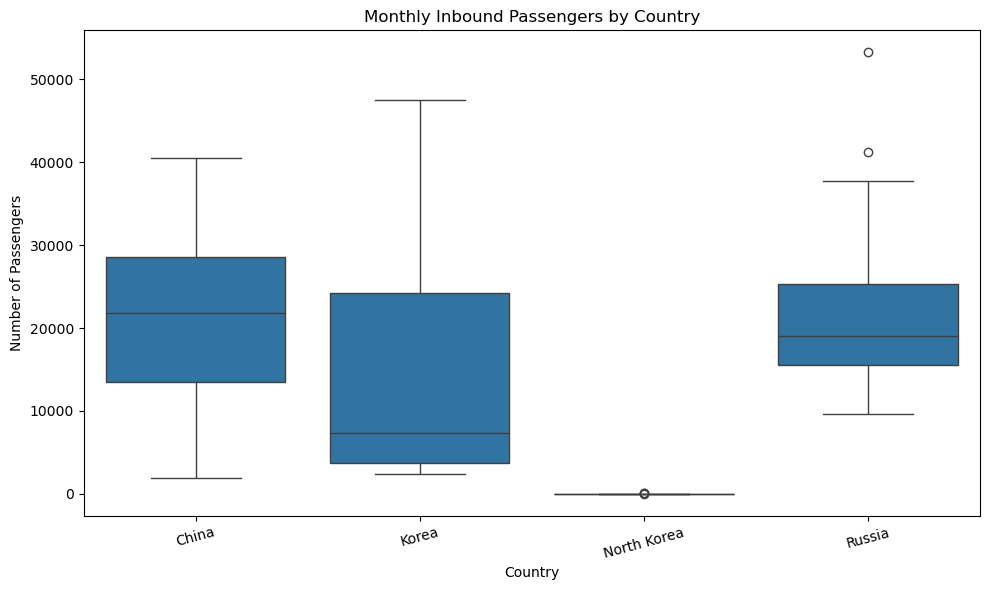

In [5]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Country", y="Passengers")

plt.title("Monthly Inbound Passengers by Country")
plt.xlabel("Country")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

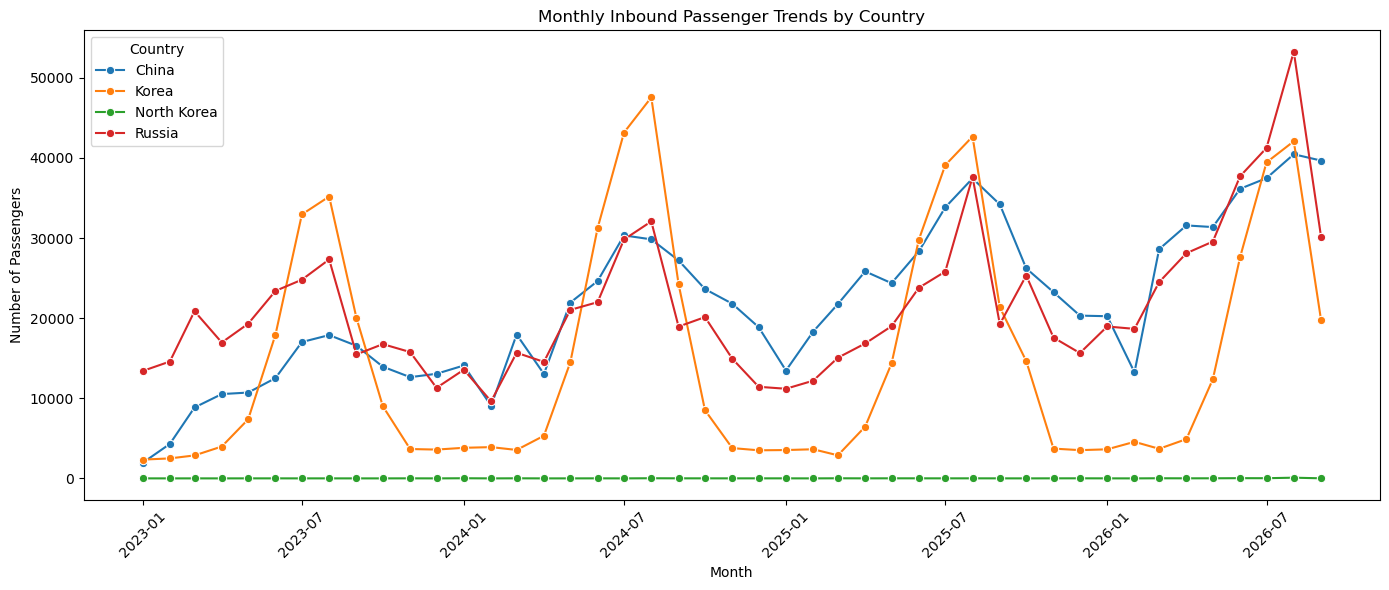

In [6]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="Month",
    y="Passengers",
    hue="Country",
    marker="o"
)

plt.title("Monthly Inbound Passenger Trends by Country")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

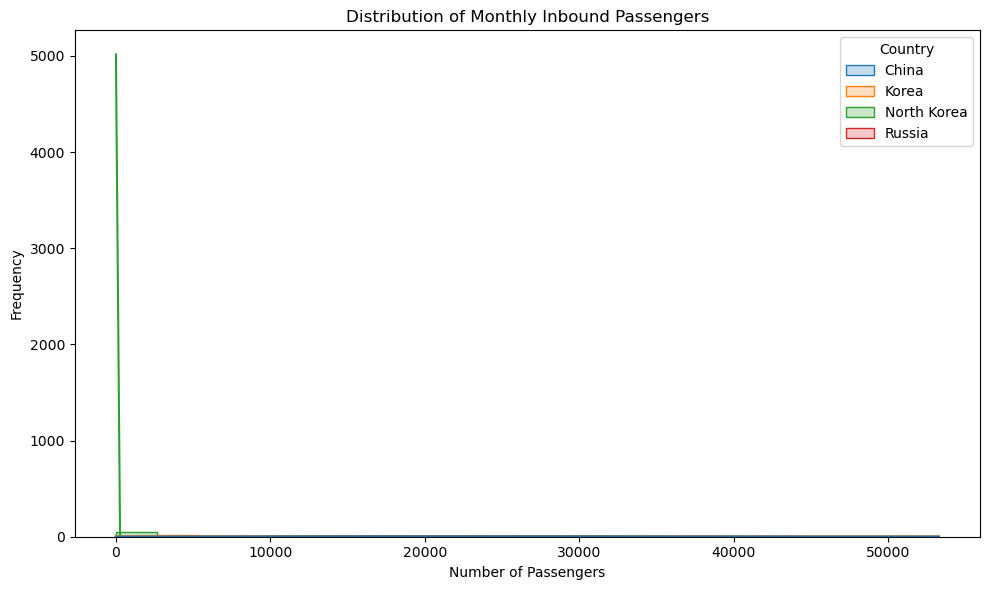

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Passengers",
    hue="Country",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Distribution of Monthly Inbound Passengers")
plt.xlabel("Number of Passengers")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

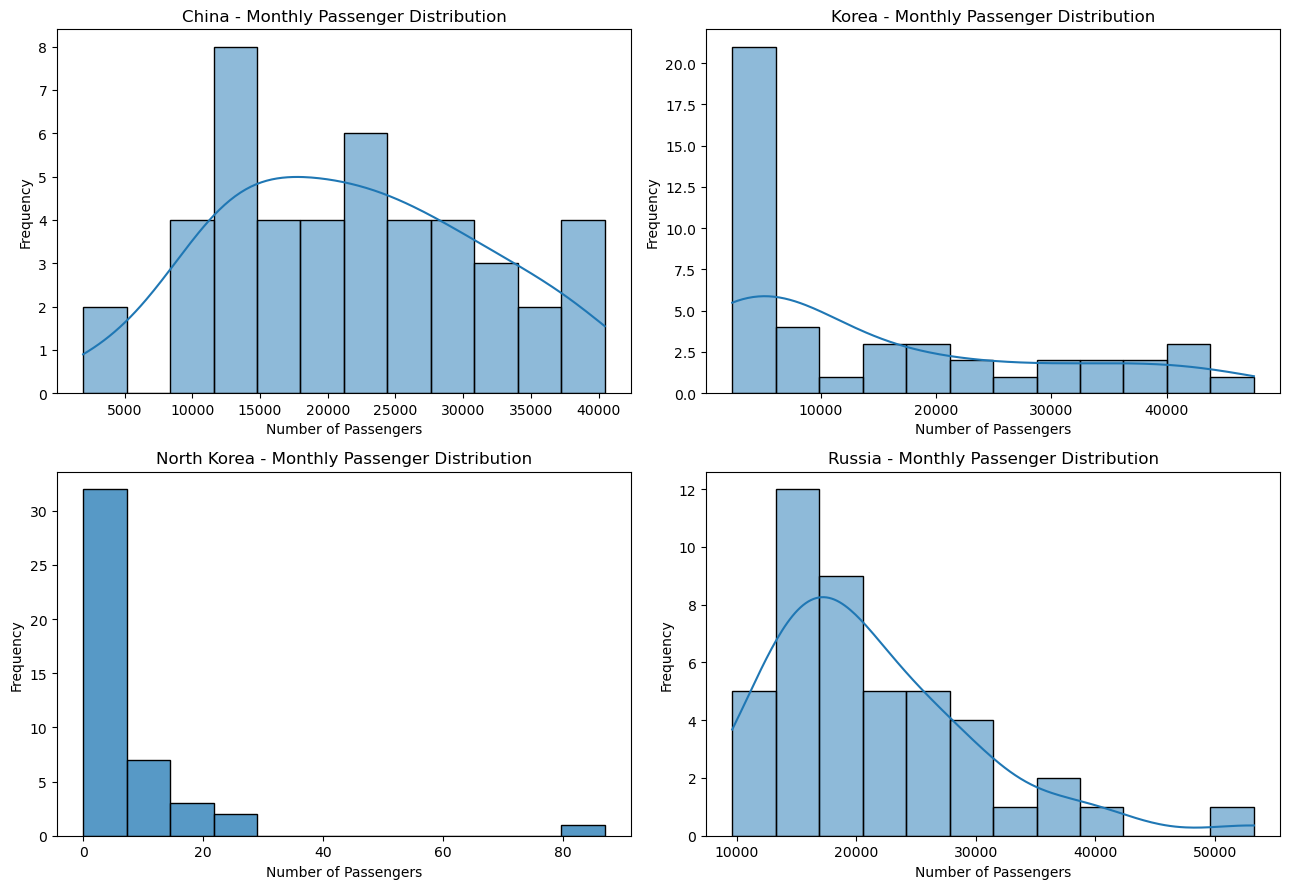

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

countries = ["China", "Korea", "North Korea", "Russia"]

for ax, country in zip(axes.flatten(), countries):
    country_data = df[df["Country"] == country]["Passengers"]

    sns.histplot(
        country_data,
        bins=12,
        kde=(country != "North Korea"),
        ax=ax
    )

    ax.set_title(f"{country} - Monthly Passenger Distribution")
    ax.set_xlabel("Number of Passengers")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [9]:
# Binomial Distribution - Korea

korea = df[df["Country"] == "Korea"]["Passengers"]

n = len(korea)
mean_value = korea.mean()

successes = (korea > mean_value).sum()
failures = n - successes

p = successes / n

print("Country: Korea")
print("Total months (n):", n)
print("Monthly average:", round(mean_value, 2))
print("Successes:", successes)
print("Failures:", failures)
print("Probability of success (p):", round(p, 4))

Country: Korea
Total months (n): 45
Monthly average: 15071.62
Successes: 16
Failures: 29
Probability of success (p): 0.3556


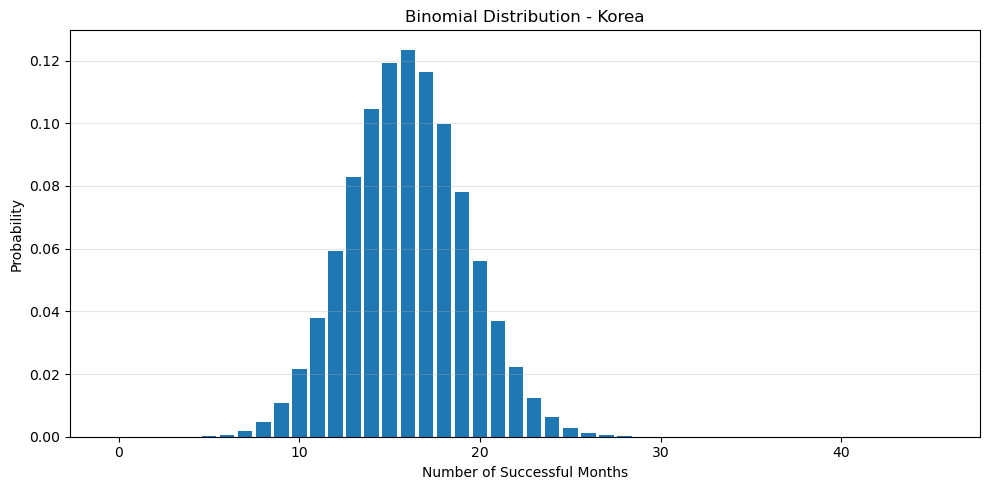

Expected successes: 16.0
Standard deviation: 3.21
Probability of exactly 16 successes: 0.1235


In [10]:
# Binomial probability distribution
n = 45
p = 16 / 45

k = np.arange(0, n + 1)

binomial_probabilities = binom.pmf(k, n, p)

plt.figure(figsize=(10, 5))

plt.bar(k, binomial_probabilities)

plt.title("Binomial Distribution - Korea")
plt.xlabel("Number of Successful Months")
plt.ylabel("Probability")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Expected successes:", round(n * p, 2))
print("Standard deviation:", round(np.sqrt(n * p * (1-p)), 2))
print("Probability of exactly 16 successes:", round(binom.pmf(16, n, p), 4))

In [11]:
# Poisson Distribution - North Korea

nk = df[df["Country"] == "North Korea"]["Passengers"]

lambda_value = nk.mean()

print("Country: North Korea")
print("Number of months:", len(nk))
print("Mean (lambda):", round(lambda_value, 2))
print("Variance:", round(nk.var(), 2))
print("Variance-to-mean ratio:", round(nk.var() / lambda_value, 2))

Country: North Korea
Number of months: 45
Mean (lambda): 7.58
Variance: 184.93
Variance-to-mean ratio: 24.4


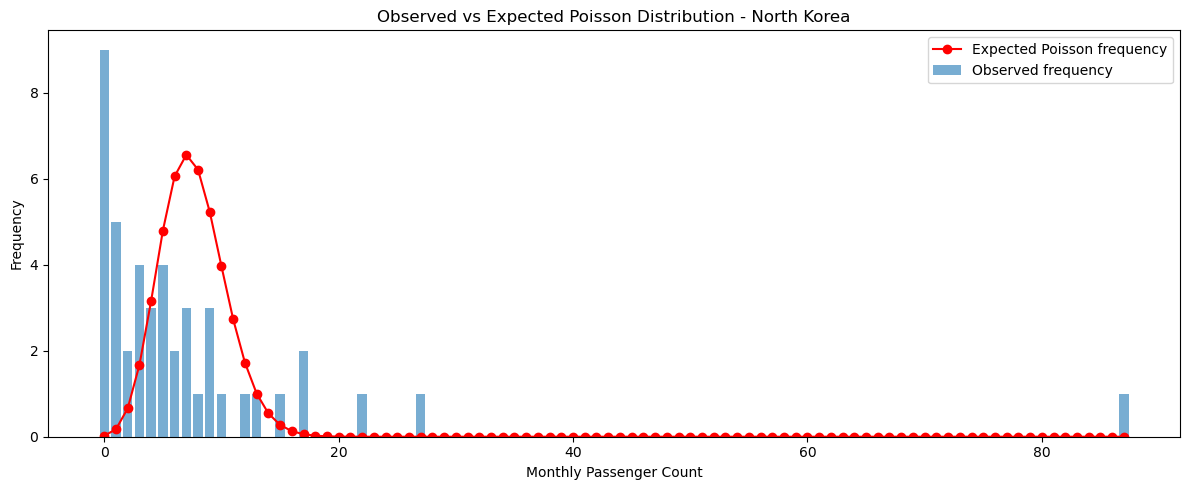

In [12]:
# Observed vs Expected Poisson frequencies

k = np.arange(0, int(nk.max()) + 1)

observed = nk.value_counts().reindex(k, fill_value=0)
expected = poisson.pmf(k, lambda_value) * len(nk)

plt.figure(figsize=(12, 5))

plt.bar(k, observed, alpha=0.6, label="Observed frequency")
plt.plot(k, expected, "ro-", label="Expected Poisson frequency")

plt.title("Observed vs Expected Poisson Distribution - North Korea")
plt.xlabel("Monthly Passenger Count")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Normal Distribution - China

china = df[df["Country"] == "China"]["Passengers"]

mu = china.mean()
sigma = china.std()

print("Country: China")
print("Mean:", round(mu, 2))
print("Standard deviation:", round(sigma, 2))
print("Skewness:", round(china.skew(), 3))

# Shapiro-Wilk normality test
stat, p_value = shapiro(china)

print("Shapiro-Wilk statistic:", round(stat, 4))
print("p-value:", round(p_value, 4))

if p_value > 0.05:
    print("The data does not show significant evidence against normality.")
else:
    print("The data shows evidence against normality.")

Country: China
Mean: 21744.44
Standard deviation: 9694.14
Skewness: 0.14
Shapiro-Wilk statistic: 0.9783
p-value: 0.5524
The data does not show significant evidence against normality.


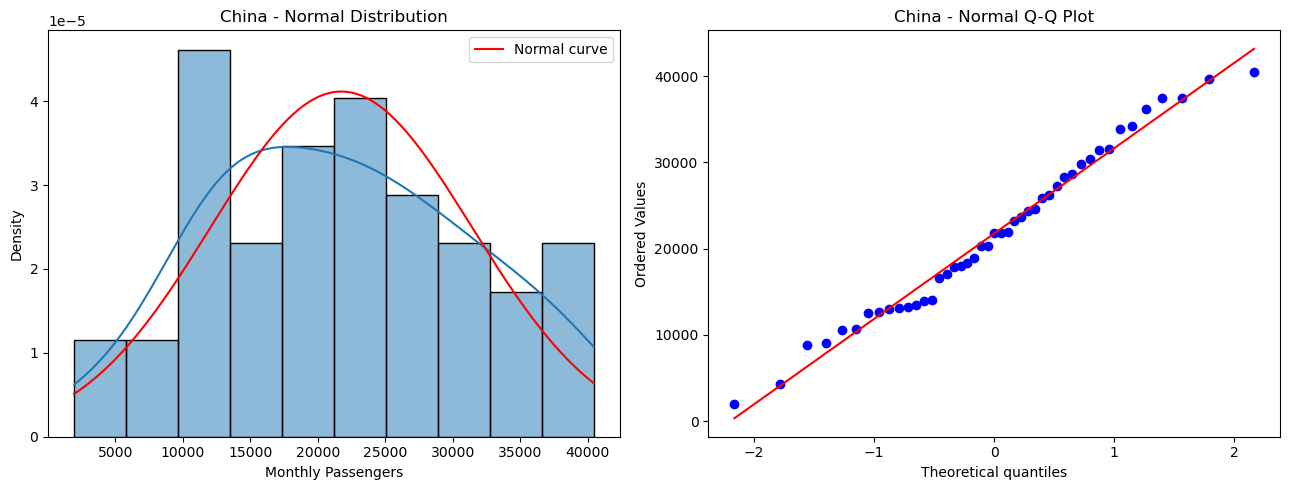

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram with normal curve
sns.histplot(china, bins=10, stat="density",
             kde=True, ax=axes[0])

x = np.linspace(china.min(), china.max(), 200)
normal_curve = norm.pdf(x, mu, sigma)

axes[0].plot(x, normal_curve, "r-", label="Normal curve")
axes[0].set_title("China - Normal Distribution")
axes[0].set_xlabel("Monthly Passengers")
axes[0].legend()

# Q-Q Plot
stats.probplot(china, dist="norm", plot=axes[1])
axes[1].set_title("China - Normal Q-Q Plot")

plt.tight_layout()
plt.show()

# Task 4 – Discussion and Comparison

## 4.1 Binomial Distribution

The Binomial Distribution was applied to the monthly passenger data from Korea. A successful month was defined as a month when the number of passengers exceeded the average of 15,071.62.

Out of 45 months, 16 months were classified as successful and 29 months as unsuccessful. The estimated probability of success was 0.3556 (35.56%).

This analysis demonstrates how the Binomial Distribution can be used to calculate the probability of a specific number of successful months.

## 4.2 Poisson Distribution

The Poisson Distribution was applied to the monthly passenger data from North Korea.

The mean was 7.58, while the variance was 184.93. The variance-to-mean ratio was 24.4, indicating substantial overdispersion.

Since the variance is considerably higher than the mean, the data does not satisfy the main Poisson assumption. Therefore, the Poisson Distribution is not a particularly suitable model for this dataset.

## 4.3 Normal Distribution

The Normal Distribution was examined using China's monthly passenger data.

The Shapiro-Wilk test produced a statistic of 0.9783 and a p-value of 0.5524. Since the p-value is greater than 0.05, there is insufficient evidence to reject the assumption of normality.

The histogram and Q-Q plot also indicate that the data is reasonably close to a normal distribution.ution.

## 4.4 Comparison and Discussion

Binomial and Poisson distributions are discrete probability distributions, whereas the Normal Distribution is continuous.

Passenger numbers are count data and therefore are discrete. However, a Normal approximation may be useful for large passenger counts when the distribution is reasonably symmetric.

The results demonstrate that selecting an appropriate probability distribution depends on the characteristics of the data and whether the assumptions of each distribution are satisfied.